# 1. Set up the notebook

Do imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Create a random number generator (used to generate example data).

In [2]:
rng = np.random.default_rng()

# 2. See an example of minimization

Create example data.

In [3]:
x = np.linspace(-5., 5., 100)
y = -1. + (x - 1.)**2

Plot example data.

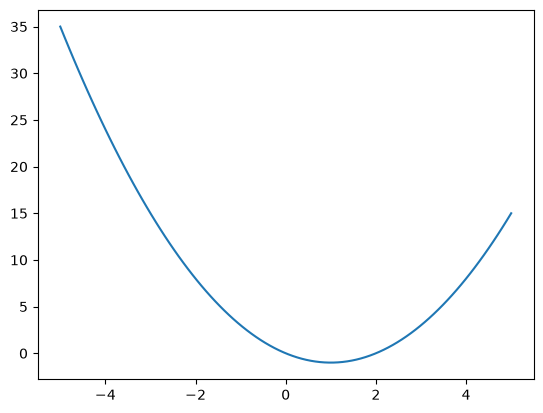

In [4]:
plt.plot(x, y)

Find the index of the minimum value of $y$.

In [5]:
i_min = np.argmin(y)

Find the minimum $y$ and the minimizing $x$.

In [6]:
y_min = y[i_min]
x_min = x[i_min]

Plot example data, showing the minimum.

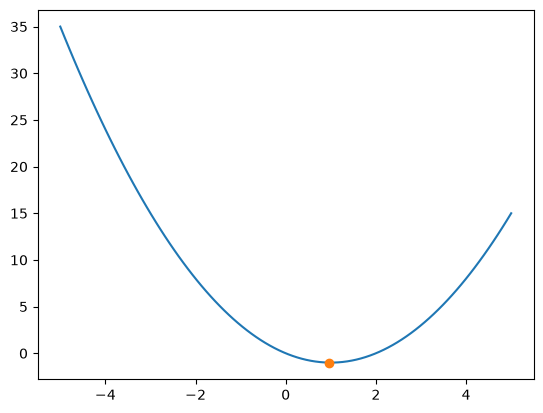

In [7]:
plt.plot(x, y)
plt.plot(x_min, y_min, '.', markersize=12)

# 3. See an example of linear regression

Create example data.

In [8]:
# number of data points
n = 20

# sample c uniformly at random in [-2, 2]
c = rng.uniform(low=-2., high=2.)

# sample n values of x uniformly at random in [-10, 10]
x = rng.uniform(low=-10., high=10., size=n)

# sample each value of y from a normal distribution about
# the corresponding value of x
y = c * x + rng.standard_normal(size=n)

Apply least-squares linear regression to estimate $c$.

Note that `y * x` performs *arithmetic* multiplication *element-wise* - that is, it produces an array of the same size as `y` and `x` with the following elements:

```
[y[0] * x[0], y[1] * x[1], ...]
```

The same is true of `x**2` - it takes the square of each *element* of `x`.

In [9]:
c_est = np.sum(y * x) / np.sum(x**2)

Print the result. We expect `c_est` to be close to `c` but not exactly the same. We also expect `c_est` to be a better and better estimate as we increase the amount of data - **try increasing `n` and see what happens**.

In [10]:
print(f'    c = {c:6.3f}')
print(f'c_est = {c_est:6.3f}')

    c =  1.519
c_est =  1.503


Plot the result.

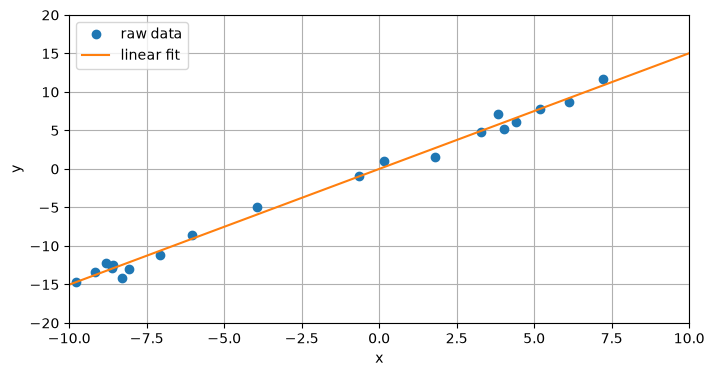

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(x, y, '.', markersize=12, label='raw data')
plt.plot([-10, 10], [c_est * -10, c_est * 10], label='linear fit')
plt.xlim(-10, 10)
plt.xlabel('x')
plt.ylim(-20, 20)
plt.ylabel('y')
plt.grid()
plt.legend()

# 3. See an example of finite difference approximation

Create example data.

In [12]:
# time step
dt = 0.01

# array of t
t = np.linspace(0., 5., 1 + int(5 / dt))

# array of x(t)
x = np.sin(t)

# array of xdot(t)
xdot = np.cos(t)

Estimate $\dot{x}(t)$ by finite difference approximation.

Remember that, if there are `n` elements in `x`, then:

* `x[1:]` is the array `[x[1], x[2], ..., x[n-1]]`
* `x[:-1]` is the array `[x[0], x[1], ..., x[n-2]]`

So:

* `x[1:] - x[:-1]` is the array `[x[1] - x[0], x[2] - x[1], ..., x[n-1] - x[n-2]]`

In [13]:
xdot_est = (x[1:] - x[:-1]) / dt

Note that the length of `xdot_est` is one less than the length of `x`.

In [14]:
print(f'length of x is {len(x)}')
print(f'length of xdot_est is {len(xdot_est)}')

length of x is 501
length of xdot_est is 500


For this reason, it is common to truncate the other data (in this case, `t`, `x`, and `xdot`), removing the last element of each array so it, too, has the same length as `xdot_est`.

In [15]:
t = t[:-1]
x = x[:-1]
xdot=xdot[:-1]

Plot $x(t)$, the true value of $\dot{x}(t)$, and our finite-difference estimate of $\dot{x}(t)$. Note that, because `xdot_est` has one fewer element than `x` and `t`, we need to plot `xdot_est` versus `t[:-1]` (i.e., all but the last element of `t`) rather than versus `t`.

(-1.5, 1.5)

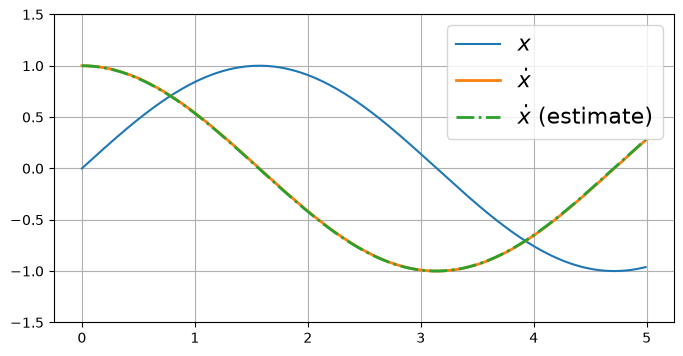

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(t, x, label='$x$')
plt.plot(t, xdot, linewidth=2, label=r'$\dot{x}$')
plt.plot(t, xdot_est, '-.', linewidth=2, label=r'$\dot{x}$ (estimate)')
plt.legend(fontsize=16)
plt.grid()
plt.ylim(-1.5, 1.5)

**Beware!** The finite difference approximation amplifies noise. Here is the result if we add a small amount of Gaussian noise to each sample of $x(t)$. Notice that $x(t)$ looks exactly the same as before, but the estimate of $\dot{x}(t)$ looks very noise (100 times noisier than $x(t)$).

(-1.5, 1.5)

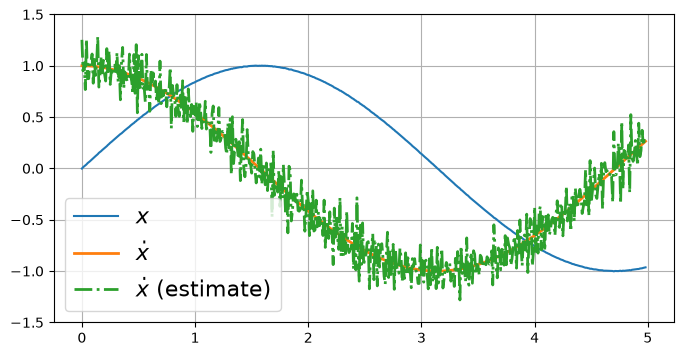

In [17]:
# create noisy data
x = np.sin(t) + 0.001 * rng.standard_normal(len(t))

# recompute estimate of xdot
xdot_est = (x[1:] - x[:-1]) / dt

# trunace other data
t = t[:-1]
x = x[:-1]
xdot=xdot[:-1]

# plot result
plt.figure(figsize=(8, 4))
plt.plot(t, x, label=r'$x$')
plt.plot(t, xdot, linewidth=2, label=r'$\dot{x}$')
plt.plot(t, xdot_est, '-.', linewidth=2, label=r'$\dot{x}$ (estimate)')
plt.legend(fontsize=16)
plt.grid()
plt.ylim(-1.5, 1.5)